# Chapter 4 - Economic dispatch and the marginal price

Power flow answers "where does the current go?". Optimisation answers "**which
plants should run, to serve the load at least cost?**". That is **economic
dispatch**; adding the network limits makes it an **optimal power flow (OPF)**.

We now give every Bohol plant a real cost (from its carrier) and let PyPSA's
solver choose the cheapest feasible mix with `n.optimize()`. Then we read the
single most important number a market produces: the **marginal price**.

**Goals of this chapter**
- Turn carrier data into a `marginal_cost` for every generator.
- Solve the dispatch with `n.optimize()` and read the **merit order**.
- Understand why `n.buses_t.marginal_price` equals the cost of the last plant
  switched on.
- See the price jump when the cheap import is scarce.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"
FIG = next(p for p in [Path("figures"), Path("../figures")] if p.exists())

buses = pd.read_excel(XLS, "buses")
lines = pd.read_excel(XLS, "lines")
carriers = pd.read_excel(XLS, "carriers")
gens = pd.read_excel(XLS, "generators")
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)

### 4.1 From carrier data to a marginal cost

The **marginal cost** is what it costs to produce one more MWh *right now*:
variable O&M plus the fuel burned, corrected for efficiency.

> marginal_cost = VOM + fuel / efficiency   (currency per MWh of electricity)

Diesel burns costly fuel at 35 % efficiency, so it is dear; hydro and solar have
almost no running cost; the grid import sits in between.

In [2]:
carriers = carriers.assign(
    marginal_cost=lambda d: (d.VOM + d.fuel / d.efficiency))
print(carriers[["name", "marginal_cost", "co2_emissions"]]
      .sort_values("marginal_cost").round(2).to_string(index=False))

   name  marginal_cost  co2_emissions
  Hydro           0.00           0.00
Battery           0.00           0.00
  Solar           0.01           0.00
   Wind           1.59           0.00
   Grid          42.73           0.11
 Diesel         157.52           0.26


### 4.2 Build the full fleet and solve

We add all 13 generators, each inheriting its carrier's marginal cost, plus the
two loads at the evening peak. With no `p_set` on the generators, the solver is
free to choose each output - that is the dispatch decision.

In [3]:
def bohol(cable_limit=138.0):
    n = pypsa.Network()
    for b in buses.itertuples():
        n.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)
    for c in carriers.itertuples():
        n.add("Carrier", c.name, co2_emissions=c.co2_emissions,
              nice_name=c.name, color=c.color)
    for l in lines.itertuples():
        n.add("Line", l.name, bus0=l.bus0, bus1=l.bus1, r=l.r, x=l.x, s_nom=l.s_nom)
    for g in gens.itertuples():
        p_nom = cable_limit if g.carrier == "Grid" else g.p_nom
        mc = float(carriers.loc[carriers.name == g.carrier, "marginal_cost"].iloc[0])
        n.add("Generator", g.name, bus=g.bus, carrier=g.carrier,
              p_nom=p_nom, marginal_cost=mc)
    h = loads_t.sum(axis=1).idxmax()
    for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                           ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
        n.add("Load", name, bus=bus, p_set=float(loads_t.loc[h, col]))
    return n

OPT = dict(solver_name="highs", solver_options={"output_flag": False}, log_to_console=False)
n = bohol()
n.optimize(**OPT)

disp = n.generators_t.p.iloc[0]
print("Peak demand:", round(n.loads.p_set.sum(), 1), "MW")
print("\nDispatch by carrier (MW):")
print(disp.groupby(n.generators.carrier).sum().round(2).to_string())
print("\nTotal operating cost:", round(float(n.objective), 1), "per hour")

Peak demand: 82.6 MW

Dispatch by carrier (MW):
carrier
Diesel     0.00
Grid      72.72
Hydro      9.90

Total operating cost: 3107.3 per hour


### 4.3 The merit order

Sort the generators by marginal cost and stack their capacity: the solver fills
demand from the cheapest plant rightward until the load is met. The last unit
needed is the **marginal unit**, and its cost sets the price.

In [4]:
mo = (n.generators.assign(dispatch=disp)
      .sort_values("marginal_cost")
      [["carrier", "p_nom", "marginal_cost", "dispatch"]])
mo["cumulative_cap"] = mo.p_nom.cumsum()
print(mo.round(2).to_string())

demand = n.loads.p_set.sum()
marginal_cost_now = n.buses_t.marginal_price.iloc[0].mean()
print(f"\nDemand {demand:.1f} MW is met below the cable; the marginal unit is the "
      f"grid import at {marginal_cost_now:.2f} /MWh.")

                 carrier  p_nom  marginal_cost  dispatch  cumulative_cap
name                                                                    
07SEVILL_G01       Hydro    2.5           0.00      2.50             2.5
07LOBOC_G02        Hydro    1.2           0.00      1.20             3.7
07LOBOC_G01        Hydro    1.2           0.00      1.20             4.9
07JANOPO_G01       Hydro    5.0           0.00      5.00             9.9
Grid_electricity    Grid  138.0          42.73     72.72           147.9
07TPLPB4_U01      Diesel    7.0         157.52     -0.00           154.9
07TPLPB4_U03      Diesel    7.0         157.52     -0.00           161.9
07TPLPB4_U02      Diesel    7.0         157.52     -0.00           168.9
07BDPP_U04        Diesel    4.0         157.52     -0.00           172.9
07BDPP_U03        Diesel    4.2         157.52     -0.00           177.1
07BDPP_U02        Diesel    4.0         157.52     -0.00           181.1
07BDPP_U01        Diesel    4.0         157.52     

### 4.4 Plot the merit-order (supply) curve

The classic staircase: width = capacity, height = marginal cost, ordered cheap
to dear. The dashed line is demand; where it crosses the staircase is the price.

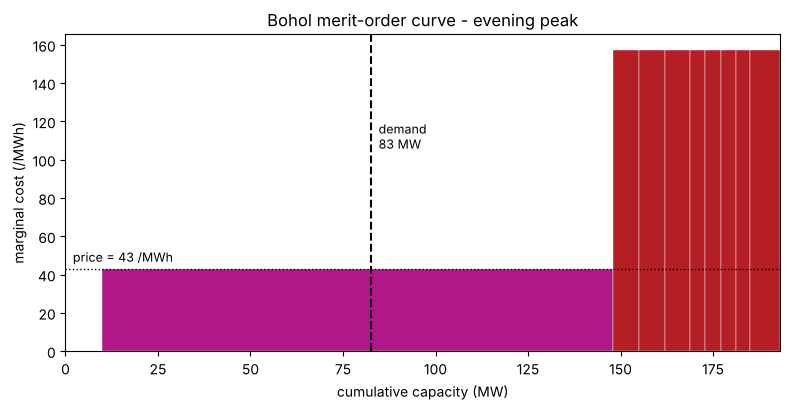

saved figures/04_merit_order.png


In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = 0.0
colors = dict(zip(carriers.name, carriers.color))
for g in mo.itertuples():
    ax.bar(x, g.marginal_cost, width=g.p_nom, align="edge",
           color=colors.get(g.carrier, "grey"), edgecolor="white", linewidth=0.3)
    x += g.p_nom
ax.axvline(demand, color="black", ls="--", lw=1.5)
ax.text(demand + 2, 120, f"demand\n{demand:.0f} MW", va="top", fontsize=9)
ax.axhline(marginal_cost_now, color="black", ls=":", lw=1)
ax.text(2, marginal_cost_now + 4, f"price = {marginal_cost_now:.0f} /MWh", fontsize=9)
ax.set_xlabel("cumulative capacity (MW)")
ax.set_ylabel("marginal cost (/MWh)")
ax.set_title("Bohol merit-order curve - evening peak")
ax.set_xlim(0, mo.cumulative_cap.max())
fig.tight_layout()
fig.savefig(FIG / "04_merit_order.png", dpi=130)
plt.show()
print("saved figures/04_merit_order.png")

### 4.5 Why the price is the marginal unit's cost

`n.buses_t.marginal_price` is the **shadow price** of the demand-balance
constraint: the extra cost of serving one more MW. Since the next MW would come
from the cheapest *un-maxed* plant, the price equals that plant's marginal cost.
Here every cheap unit except the grid is maxed out, the grid is partly loaded,
so the grid sets the price - **42.73 /MWh at all three buses** (no line is
congested, so one uniform price).

In [6]:
print(n.buses_t.marginal_price.iloc[0].round(2).to_string())

name
07CORELLA    42.73
07TAPAL      42.73
07UBAY       42.73


### 4.6 Scarcity: cap the cheap import

What if the submarine cable can only deliver 40 MW (a maintenance limit)? The
solver must now start the **diesel** units to cover the gap. Diesel becomes the
marginal unit, and the price jumps to its cost.

In [7]:
m = bohol(cable_limit=40.0)
m.optimize(**OPT)
disp_m = m.generators_t.p.iloc[0]
print("Dispatch by carrier with the cable capped at 40 MW (MW):")
print(disp_m.groupby(m.generators.carrier).sum().round(2).to_string())
print("\nPrice now:", round(m.buses_t.marginal_price.iloc[0].mean(), 2), "/MWh",
      "(diesel is marginal)")
print("Operating cost:", round(float(m.objective), 1), "per hour",
      f"(was {float(n.objective):.0f}) -> scarcity more than doubles the cost.")

Dispatch by carrier with the cable capped at 40 MW (MW):
carrier
Diesel    32.72
Grid      40.00
Hydro      9.90

Price now: 157.52 /MWh (diesel is marginal)
Operating cost: 6863.4 per hour (was 3107) -> scarcity more than doubles the cost.


## Summary of Chapter 4

- `n.optimize()` chooses the least-cost dispatch; the **merit order** (cheap to
  dear) explains its choice at a glance.
- On a normal peak, Bohol runs **hydro + cable import**, diesel stays off, and
  the uniform price is **42.73 /MWh** - the grid import's cost.
- The **marginal price** always equals the cost of the last unit switched on.
  Cap the cheap cable and diesel sets the price at **157.52 /MWh**: scarcity is
  expensive.
- Next chapter we add a full 24-hour day, renewables and a battery, so the
  dispatch changes hour by hour.